In [2]:
# =====================================
# CNN1D ONLY TIMESERIES EXPERIMENT
# =====================================

import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.run.model.run_timeseries_classifier import RunTimeSeriesCNN
from src.run.preprocess.config import _project_path

In [3]:
# =====================================
# EPOCHS EXPERIMENT
# =====================================

results = []

epochs_values = [25, 50, 75, 100, 150, 200]

for epochs in epochs_values:

    print(f"\n=== Running experiment with epochs={epochs} ===")

    runner = RunTimeSeriesCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),

        batch_size=32,

        # Iperparametro sotto test
        epochs=epochs,

        learning_rate=1e-3,
        regularization=1e-6,
        n_splits=5,

        normalize=True,
        seed=42,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            "experiments/test_iperparametri/cnn1D(timeseries)/"
            f"epochs/epochs_{epochs}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    averages = summary["averages"]

    # =====================================
    # SAVE RESULTS
    # =====================================

    results.append({
        "epochs": epochs,

        "accuracy": averages["val_accuracy"],
        "f1": averages["val_f1"],
        "auc": averages["val_auc"],
        "precision": averages["val_precision"],
        "recall": averages["val_recall"],
        "specificity": averages["val_specificity"],
    })

    # =====================================
    # PRINT RESULTS
    # =====================================

    print(f"\n=== Results for epochs={epochs} ===")

    print(f"Accuracy:    {averages['val_accuracy']:.4f}")
    print(f"F1 Score:    {averages['val_f1']:.4f}")
    print(f"AUC:         {averages['val_auc']:.4f}")
    print(f"Precision:   {averages['val_precision']:.4f}")
    print(f"Recall:      {averages['val_recall']:.4f}")
    print(f"Specificity: {averages['val_specificity']:.4f}")


# =====================================
# RESULTS DATAFRAME
# =====================================

df_epochs = pd.DataFrame(results)

print("\n=== EPOCHS EXPERIMENT RESULTS ===")

display(
    df_epochs.sort_values(
        by="auc",
        ascending=False
    )
)


=== Running experiment with epochs=25 ===
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7154 | val_loss=0.6763 | train_accuracy=0.5083 | val_accuracy=0.6000
Fold 01 | Epoch 02 | train_loss=0.6679 | val_loss=0.6662 | train_accuracy=0.5917 | val_accuracy=0.6333
Fold 01 | Epoch 03 | train_loss=0.6510 | val_loss=0.6642 | train_accuracy=0.6417 | val_accuracy=0.6000
Fold 01 | Epoch 04 | train_loss=0.6245 | val_loss=0.6826 | train_accuracy=0.6250 | val_accuracy=0.6333
Fold 01 | Epoch 05 | train_loss=0.6214 | val_loss=0.7283 | train_accuracy=0.6583 | val_accuracy=0.5667
Fold 01 | Epoch 06 | train_loss=0.6258 | val_loss=0.7182 | train_accuracy=0.6500 | val_accuracy=0.6000
Fold 01 | Epoch 07 | train_loss=0.6483 | val_loss=0.7067 | train_accuracy=0.6250 | val_accuracy=0.5667
Fold 01 | Epoch 08 | train_loss=0.6192 | val_loss=0.6859 | train_accuracy=0.7000 | val_accuracy=0.6333
Fold 01 | Epoch 09 | train_loss=0.6057 | val_loss=0.6913 | train_acc

,epochs,accuracy,f1,auc,precision,recall,specificity
5,200,0.593333,0.656975,0.737500,0.580844,0.816071,0.358929
4,150,0.593333,0.672178,0.709821,0.557391,0.857143,0.319643
2,75,0.593333,0.679656,0.706250,0.553825,0.885714,0.292857
3,100,0.586667,0.689883,0.695536,0.555026,0.928571,0.242857
1,50,0.580000,0.690520,0.683036,0.547826,0.944643,0.223214
0,25,0.600000,0.664582,0.657143,0.560919,0.819643,0.382143


In [4]:
# =====================================
# LEARNING RATE EXPERIMENT
# =====================================

results = []

learning_rates = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]

for lr in learning_rates:

    print(f"\n=== Running experiment with learning_rate={lr} ===")

    runner = RunTimeSeriesCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),

        batch_size=32,

        epochs=25,

        # Iperparametro sotto test
        learning_rate=lr,

        regularization=1e-6,
        n_splits=5,

        normalize=True,
        seed=42,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            "experiments/test_iperparametri/cnn1D(timeseries)/"
            f"learning_rate/lr_{lr}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    averages = summary["averages"]

    # =====================================
    # SAVE RESULTS
    # =====================================

    results.append({
        "learning_rate": lr,

        "accuracy": averages["val_accuracy"],
        "f1": averages["val_f1"],
        "auc": averages["val_auc"],
        "precision": averages["val_precision"],
        "recall": averages["val_recall"],
        "specificity": averages["val_specificity"],
    })

    # =====================================
    # PRINT RESULTS
    # =====================================

    print(f"\n=== Results for learning_rate={lr} ===")

    print(f"Accuracy:    {averages['val_accuracy']:.4f}")
    print(f"F1 Score:    {averages['val_f1']:.4f}")
    print(f"AUC:         {averages['val_auc']:.4f}")
    print(f"Precision:   {averages['val_precision']:.4f}")
    print(f"Recall:      {averages['val_recall']:.4f}")
    print(f"Specificity: {averages['val_specificity']:.4f}")


# =====================================
# RESULTS DATAFRAME
# =====================================

df_lr = pd.DataFrame(results)

print("\n=== LEARNING RATE EXPERIMENT RESULTS ===")

display(
    df_lr.sort_values(
        by="auc",
        ascending=False
    )
)


=== Running experiment with learning_rate=0.01 ===
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=1.0695 | val_loss=0.7527 | train_accuracy=0.5167 | val_accuracy=0.5333
Fold 01 | Epoch 02 | train_loss=0.6760 | val_loss=0.6590 | train_accuracy=0.6000 | val_accuracy=0.6333
Fold 01 | Epoch 03 | train_loss=0.6804 | val_loss=0.6863 | train_accuracy=0.5583 | val_accuracy=0.5333
Fold 01 | Epoch 04 | train_loss=0.6373 | val_loss=0.7330 | train_accuracy=0.6167 | val_accuracy=0.5333
Fold 01 | Epoch 05 | train_loss=0.6575 | val_loss=0.6671 | train_accuracy=0.6083 | val_accuracy=0.5333
Fold 01 | Epoch 06 | train_loss=0.6516 | val_loss=0.6651 | train_accuracy=0.6000 | val_accuracy=0.5333
Fold 01 | Epoch 07 | train_loss=0.6650 | val_loss=0.6874 | train_accuracy=0.6000 | val_accuracy=0.4667
Fold 01 | Epoch 08 | train_loss=0.6375 | val_loss=0.7187 | train_accuracy=0.6417 | val_accuracy=0.4667
Fold 01 | Epoch 09 | train_loss=0.6354 | val_loss=0.6997 | 

,learning_rate,accuracy,f1,auc,precision,recall,specificity
0,0.010000,0.580000,0.678436,0.687500,0.543724,0.903571,0.258929
2,0.000100,0.600000,0.612082,0.666071,0.560919,0.733929,0.457143
1,0.001000,0.600000,0.664582,0.657143,0.560919,0.819643,0.382143
3,0.000010,0.520000,0.453638,0.652679,0.407566,0.608929,0.432143
4,0.000001,0.533333,0.337902,0.587500,0.540000,0.425000,0.623214


In [6]:
# =====================================
# REGULARIZATION EXPERIMENT
# =====================================

results = []

regularizations = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]

for regularization in regularizations:

    print(
        f"\n=== Running experiment with regularization={regularization} ==="
    )

    runner = RunTimeSeriesCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),

        batch_size=32,

        epochs=25,

        learning_rate=1e-4,

        # Iperparametro sotto test
        regularization=regularization,

        n_splits=5,

        normalize=True,
        seed=42,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            "experiments/test_iperparametri/cnn1D(timeseries)/"
            f"regularization/reg_{regularization}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    averages = summary["averages"]

    # =====================================
    # SAVE RESULTS
    # =====================================

    results.append({
        "regularization": regularization,

        "accuracy": averages["val_accuracy"],
        "f1": averages["val_f1"],
        "auc": averages["val_auc"],
        "precision": averages["val_precision"],
        "recall": averages["val_recall"],
        "specificity": averages["val_specificity"],
    })

    # =====================================
    # PRINT RESULTS
    # =====================================

    print(
        f"\n=== Results for regularization={regularization} ==="
    )

    print(f"Accuracy:    {averages['val_accuracy']:.4f}")
    print(f"F1 Score:    {averages['val_f1']:.4f}")
    print(f"AUC:         {averages['val_auc']:.4f}")
    print(f"Precision:   {averages['val_precision']:.4f}")
    print(f"Recall:      {averages['val_recall']:.4f}")
    print(f"Specificity: {averages['val_specificity']:.4f}")


# =====================================
# RESULTS DATAFRAME
# =====================================

df_reg = pd.DataFrame(results)

print("\n=== REGULARIZATION EXPERIMENT RESULTS ===")

display(
    df_reg.sort_values(
        by="auc",
        ascending=False
    )
)


=== Running experiment with regularization=0.01 ===
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.6991 | val_loss=0.7021 | train_accuracy=0.5167 | val_accuracy=0.4667
Fold 01 | Epoch 02 | train_loss=0.6865 | val_loss=0.6952 | train_accuracy=0.5167 | val_accuracy=0.4667
Fold 01 | Epoch 03 | train_loss=0.6851 | val_loss=0.6905 | train_accuracy=0.5750 | val_accuracy=0.4333
Fold 01 | Epoch 04 | train_loss=0.6606 | val_loss=0.6850 | train_accuracy=0.5917 | val_accuracy=0.5667
Fold 01 | Epoch 05 | train_loss=0.6660 | val_loss=0.6807 | train_accuracy=0.6500 | val_accuracy=0.6333
Fold 01 | Epoch 06 | train_loss=0.6576 | val_loss=0.6776 | train_accuracy=0.5917 | val_accuracy=0.6333
Fold 01 | Epoch 07 | train_loss=0.6655 | val_loss=0.6756 | train_accuracy=0.5750 | val_accuracy=0.6333
Fold 01 | Epoch 08 | train_loss=0.6526 | val_loss=0.6740 | train_accuracy=0.6167 | val_accuracy=0.6333
Fold 01 | Epoch 09 | train_loss=0.6398 | val_loss=0.6734 |

,regularization,accuracy,f1,auc,precision,recall,specificity
4,0.000001,0.6,0.612082,0.666071,0.560919,0.733929,0.457143
2,0.000100,0.6,0.609831,0.665179,0.563354,0.721429,0.471429
3,0.000010,0.6,0.612082,0.664286,0.560919,0.733929,0.457143
0,0.010000,0.6,0.594275,0.663393,0.563354,0.707143,0.483929
1,0.001000,0.6,0.609831,0.663393,0.563354,0.721429,0.471429


In [7]:
# =====================================
# BATCH SIZE EXPERIMENT
# =====================================

results = []

batch_sizes = [8, 16, 32, 64]

for batch_size in batch_sizes:

    print(
        f"\n=== Running experiment with batch_size={batch_size} ==="
    )

    runner = RunTimeSeriesCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),

        # Iperparametro sotto test
        batch_size=batch_size,

        epochs=25,
        learning_rate=1e-4,
        regularization=1e-6,
        n_splits=5,

        normalize=True,
        seed=42,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            "experiments/test_iperparametri/cnn1D(timeseries)/"
            f"batch_size/batch_{batch_size}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    averages = summary["averages"]

    # =====================================
    # SAVE RESULTS
    # =====================================

    results.append({
        "batch_size": batch_size,

        "accuracy": averages["val_accuracy"],
        "f1": averages["val_f1"],
        "auc": averages["val_auc"],
        "precision": averages["val_precision"],
        "recall": averages["val_recall"],
        "specificity": averages["val_specificity"],
    })

    # =====================================
    # PRINT RESULTS
    # =====================================

    print(
        f"\n=== Results for batch_size={batch_size} ==="
    )

    print(f"Accuracy:    {averages['val_accuracy']:.4f}")
    print(f"F1 Score:    {averages['val_f1']:.4f}")
    print(f"AUC:         {averages['val_auc']:.4f}")
    print(f"Precision:   {averages['val_precision']:.4f}")
    print(f"Recall:      {averages['val_recall']:.4f}")
    print(f"Specificity: {averages['val_specificity']:.4f}")


# =====================================
# RESULTS DATAFRAME
# =====================================

df_batch = pd.DataFrame(results)

print("\n=== BATCH SIZE EXPERIMENT RESULTS ===")

display(
    df_batch.sort_values(
        by="auc",
        ascending=False
    )
)


=== Running experiment with batch_size=8 ===
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7010 | val_loss=0.6916 | train_accuracy=0.4833 | val_accuracy=0.4333
Fold 01 | Epoch 02 | train_loss=0.6838 | val_loss=0.6786 | train_accuracy=0.5417 | val_accuracy=0.6000
Fold 01 | Epoch 03 | train_loss=0.6691 | val_loss=0.6701 | train_accuracy=0.6167 | val_accuracy=0.6000
Fold 01 | Epoch 04 | train_loss=0.6482 | val_loss=0.6651 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 05 | train_loss=0.6495 | val_loss=0.6639 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 06 | train_loss=0.6465 | val_loss=0.6655 | train_accuracy=0.6333 | val_accuracy=0.6333
Fold 01 | Epoch 07 | train_loss=0.6491 | val_loss=0.6645 | train_accuracy=0.6333 | val_accuracy=0.6333
Fold 01 | Epoch 08 | train_loss=0.6241 | val_loss=0.6602 | train_accuracy=0.6500 | val_accuracy=0.6000
Fold 01 | Epoch 09 | train_loss=0.6274 | val_loss=0.6558 | train_

,batch_size,accuracy,f1,auc,precision,recall,specificity
0,8,0.613333,0.674646,0.691071,0.573360,0.821429,0.408929
1,16,0.606667,0.671043,0.683036,0.568617,0.821429,0.396429
3,64,0.573333,0.549085,0.672321,0.442762,0.732143,0.403571
2,32,0.600000,0.612082,0.666071,0.560919,0.733929,0.457143


In [11]:
# =====================================
# EARLY STOPPING EXPERIMENT
# =====================================

results = []

early_stopping_values = [5, 10, 15, 20, 25]

for patience in early_stopping_values:

    print(
        f"\n=== Running experiment with early_stopping_patience={patience} ==="
    )

    runner = RunTimeSeriesCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),

        batch_size=8,

        epochs=25,
        learning_rate=1e-4,
        regularization=1e-6,
        n_splits=5,

        normalize=True,
        seed=42,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            "experiments/test_iperparametri/cnn1D(timeseries)/"
            f"early_stopping/patience_{patience}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            # Iperparametro sotto test
            "early_stopping_patience": patience,

            "min_delta": 1e-3,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    averages = summary["averages"]

    # =====================================
    # SAVE RESULTS
    # =====================================

    results.append({
        "early_stopping_patience": patience,

        "accuracy": averages["val_accuracy"],
        "f1": averages["val_f1"],
        "auc": averages["val_auc"],
        "precision": averages["val_precision"],
        "recall": averages["val_recall"],
        "specificity": averages["val_specificity"],
    })

    # =====================================
    # PRINT RESULTS
    # =====================================

    print(
        f"\n=== Results for early_stopping_patience={patience} ==="
    )

    print(f"Accuracy:    {averages['val_accuracy']:.4f}")
    print(f"F1 Score:    {averages['val_f1']:.4f}")
    print(f"AUC:         {averages['val_auc']:.4f}")
    print(f"Precision:   {averages['val_precision']:.4f}")
    print(f"Recall:      {averages['val_recall']:.4f}")
    print(f"Specificity: {averages['val_specificity']:.4f}")


# =====================================
# RESULTS DATAFRAME
# =====================================

df_early_stopping = pd.DataFrame(results)

print("\n=== EARLY STOPPING EXPERIMENT RESULTS ===")

display(
    df_early_stopping.sort_values(
        by="auc",
        ascending=False
    )
)


=== Running experiment with early_stopping_patience=5 ===
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7010 | val_loss=0.6916 | train_accuracy=0.4833 | val_accuracy=0.4333
Fold 01 | Epoch 02 | train_loss=0.6838 | val_loss=0.6786 | train_accuracy=0.5417 | val_accuracy=0.6000
Fold 01 | Epoch 03 | train_loss=0.6691 | val_loss=0.6701 | train_accuracy=0.6167 | val_accuracy=0.6000
Fold 01 | Epoch 04 | train_loss=0.6482 | val_loss=0.6651 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 05 | train_loss=0.6495 | val_loss=0.6639 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 06 | train_loss=0.6465 | val_loss=0.6655 | train_accuracy=0.6333 | val_accuracy=0.6333
Fold 01 | Epoch 07 | train_loss=0.6491 | val_loss=0.6645 | train_accuracy=0.6333 | val_accuracy=0.6333
Fold 01 | Epoch 08 | train_loss=0.6241 | val_loss=0.6602 | train_accuracy=0.6500 | val_accuracy=0.6000
Fold 01 | Epoch 09 | train_loss=0.6274 | val_loss=0.

,early_stopping_patience,accuracy,f1,auc,precision,recall,specificity
2,15,0.633333,0.685506,0.693750,0.598481,0.808929,0.466071
1,10,0.613333,0.674646,0.691964,0.573360,0.821429,0.408929
3,20,0.613333,0.674646,0.691071,0.573360,0.821429,0.408929
4,25,0.613333,0.674646,0.691071,0.573360,0.821429,0.408929
0,5,0.620000,0.678695,0.683929,0.579289,0.821429,0.423214


In [12]:
# =====================================
# MIN DELTA EXPERIMENT
# =====================================

results = []

min_delta_values = [0.0, 1e-4, 1e-3, 1e-2, 1e-1]

for min_delta in min_delta_values:

    print(
        f"\n=== Running experiment with min_delta={min_delta} ==="
    )

    runner = RunTimeSeriesCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),

        batch_size=8,

        epochs=25,
        learning_rate=1e-4,
        regularization=1e-6,
        n_splits=5,

        normalize=True,
        seed=42,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            "experiments/test_iperparametri/cnn1D(timeseries)/"
            f"min_delta/min_delta_{min_delta}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": 15,

            # Iperparametro sotto test
            "min_delta": min_delta,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    averages = summary["averages"]

    # =====================================
    # SAVE RESULTS
    # =====================================

    results.append({
        "min_delta": min_delta,

        "accuracy": averages["val_accuracy"],
        "f1": averages["val_f1"],
        "auc": averages["val_auc"],
        "precision": averages["val_precision"],
        "recall": averages["val_recall"],
        "specificity": averages["val_specificity"],
    })

    # =====================================
    # PRINT RESULTS
    # =====================================

    print(
        f"\n=== Results for min_delta={min_delta} ==="
    )

    print(f"Accuracy:    {averages['val_accuracy']:.4f}")
    print(f"F1 Score:    {averages['val_f1']:.4f}")
    print(f"AUC:         {averages['val_auc']:.4f}")
    print(f"Precision:   {averages['val_precision']:.4f}")
    print(f"Recall:      {averages['val_recall']:.4f}")
    print(f"Specificity: {averages['val_specificity']:.4f}")


# =====================================
# RESULTS DATAFRAME
# =====================================

df_min_delta = pd.DataFrame(results)

print("\n=== MIN DELTA EXPERIMENT RESULTS ===")

display(
    df_min_delta.sort_values(
        by="auc",
        ascending=False
    )
)


=== Running experiment with min_delta=0.0 ===
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7010 | val_loss=0.6916 | train_accuracy=0.4833 | val_accuracy=0.4333
Fold 01 | Epoch 02 | train_loss=0.6838 | val_loss=0.6786 | train_accuracy=0.5417 | val_accuracy=0.6000
Fold 01 | Epoch 03 | train_loss=0.6691 | val_loss=0.6701 | train_accuracy=0.6167 | val_accuracy=0.6000
Fold 01 | Epoch 04 | train_loss=0.6482 | val_loss=0.6651 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 05 | train_loss=0.6495 | val_loss=0.6639 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 06 | train_loss=0.6465 | val_loss=0.6655 | train_accuracy=0.6333 | val_accuracy=0.6333
Fold 01 | Epoch 07 | train_loss=0.6491 | val_loss=0.6645 | train_accuracy=0.6333 | val_accuracy=0.6333
Fold 01 | Epoch 08 | train_loss=0.6241 | val_loss=0.6602 | train_accuracy=0.6500 | val_accuracy=0.6000
Fold 01 | Epoch 09 | train_loss=0.6274 | val_loss=0.6558 | train

,min_delta,accuracy,f1,auc,precision,recall,specificity
0,0.0000,0.633333,0.685506,0.693750,0.598481,0.808929,0.466071
1,0.0001,0.633333,0.685506,0.693750,0.598481,0.808929,0.466071
2,0.0010,0.633333,0.685506,0.693750,0.598481,0.808929,0.466071
3,0.0100,0.633333,0.685506,0.692857,0.598481,0.808929,0.466071
4,0.1000,0.626667,0.687970,0.652679,0.585325,0.837500,0.423214


[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7010 | val_loss=0.6916 | train_accuracy=0.4833 | val_accuracy=0.4333
Fold 01 | Epoch 02 | train_loss=0.6838 | val_loss=0.6786 | train_accuracy=0.5417 | val_accuracy=0.6000
Fold 01 | Epoch 03 | train_loss=0.6691 | val_loss=0.6701 | train_accuracy=0.6167 | val_accuracy=0.6000
Fold 01 | Epoch 04 | train_loss=0.6482 | val_loss=0.6651 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 05 | train_loss=0.6495 | val_loss=0.6639 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 06 | train_loss=0.6465 | val_loss=0.6655 | train_accuracy=0.6333 | val_accuracy=0.6333
Fold 01 | Epoch 07 | train_loss=0.6491 | val_loss=0.6645 | train_accuracy=0.6333 | val_accuracy=0.6333
Fold 01 | Epoch 08 | train_loss=0.6241 | val_loss=0.6602 | train_accuracy=0.6500 | val_accuracy=0.6000
Fold 01 | Epoch 09 | train_loss=0.6274 | val_loss=0.6558 | train_accuracy=0.6333 | val_accuracy=0.6000
Fold 01 

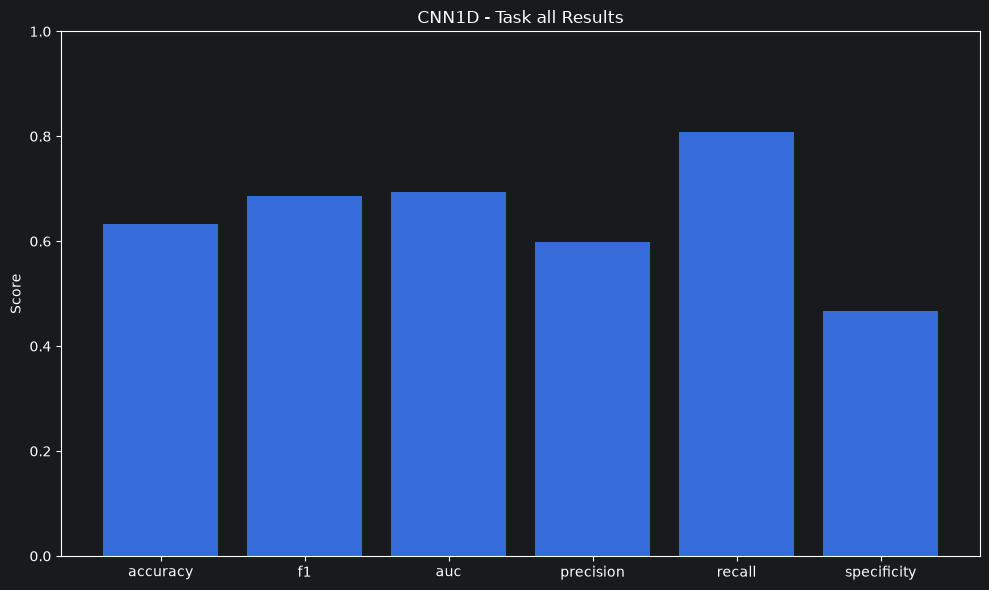

In [13]:
# =====================================
# RUN EXPERIMENT
# =====================================

runner = RunTimeSeriesCNN(
    data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
    metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
    tasks=[4, 8],
    feature_names=("x", "y"),
    engineered_features=("speed", "pressure_derivative"),
    batch_size=8,
    epochs=25,
    learning_rate=1e-4,
    regularization=1e-6,
    n_splits=5,
    normalize=True,
    seed=42,
    device=("cuda" if torch.cuda.is_available() else "cpu"),
    output_dir=_project_path("experiments/cnn1D/timeseries + cnn/task_4_8/xy_speed_pressure_derivative"),
    training_cfg={
        "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
        "monitor_metric": "auc",
        "early_stopping_patience": 15,
        "min_delta": 1e-4,
        "results_writer": "csv",
        "save_metrics": True,
    },
)

summary = runner.run()

# =====================================
# RESULTS
# =====================================

averages = summary["averages"]

print("\n=== FINAL RESULTS ===")

print(f"Accuracy:    {averages['val_accuracy']:.4f}")
print(f"F1 Score:    {averages['val_f1']:.4f}")
print(f"AUC:         {averages['val_auc']:.4f}")
print(f"Precision:   {averages['val_precision']:.4f}")
print(f"Recall:      {averages['val_recall']:.4f}")
print(f"Specificity: {averages['val_specificity']:.4f}")

# =====================================
# BUILD DATAFRAME
# =====================================

df = pd.DataFrame([{
    "accuracy": averages["val_accuracy"],
    "f1": averages["val_f1"],
    "auc": averages["val_auc"],
    "precision": averages["val_precision"],
    "recall": averages["val_recall"],
    "specificity": averages["val_specificity"],
}])

# =====================================
# PLOT
# =====================================

metrics = [
    "accuracy",
    "f1",
    "auc",
    "precision",
    "recall",
    "specificity",
]

values = [
    averages[f"val_{m}"]
    for m in metrics
]

plt.figure(figsize=(10, 6))

plt.bar(
    metrics,
    values,
)

plt.ylim(0, 1)

plt.ylabel("Score")

plt.title(
    "CNN1D - Task all Results"
)

plt.tight_layout()

plt.show()
